# Predicting pIC50 for ZINC22 compound sets

Both compound sets in this notebook were obtained from ZINC22. The scaffold set contains 1,648 compounds retrieved with a similarity search using the default settings. The random set contains 10,000 compounds retrieved with a ZINC22 random search query. The source files are `data/raw/scaffold_zinc22.csv` and `data/raw/random_zinc22.csv`.

The notebook predicts every compound present in each input file.

The same saved Morgan radius-2 model is applied to both sets. Results are saved separately in `results/tables/`.

In [10]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# Locate the repository root whether Jupyter was started in the root or src/.
PROJECT_ROOT = Path.cwd().resolve()
for parent in (PROJECT_ROOT, *PROJECT_ROOT.parents):
    if (parent / ".git").exists():
        PROJECT_ROOT = parent
        break
else:
    raise RuntimeError("Could not locate the project root (expected a .git directory).")

MODEL_PATH = PROJECT_ROOT / "models" / "final_svr_morgan2.joblib"
DATASETS = {
    "scaffold": {
        "input": PROJECT_ROOT / "data" / "raw" / "scaffold_zinc22.csv",
        "output": PROJECT_ROOT / "results" / "tables" / "scaffold_zinc22_predicted_pIC50.csv",
        "alignment_column": "alignment",
    },
    "random": {
        "input": PROJECT_ROOT / "data" / "raw" / "random_zinc22.csv",
        "output": PROJECT_ROOT / "results" / "tables" / "random_zinc22_predicted_pIC50.csv",
        "smiles_column": "SMILES",
        "id_column": "zincid",
    },
}

# Match the Morgan radius-2, 2048-bit fingerprint used to train the model.
MORGAN2 = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Trained model not found: {MODEL_PATH}")

model = joblib.load(MODEL_PATH)
print(f"Loaded model: {MODEL_PATH}")

def smiles_to_morgan2(smiles):
    """Convert a SMILES string to a Morgan radius-2 fingerprint."""
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return None
    return MORGAN2.GetFingerprintAsNumPy(molecule)

def predict_dataset(name, settings):
    """Predict and save pIC50 and IC50 values for one configured compound set."""
    input_path = settings["input"]
    output_path = settings["output"]
    if not input_path.is_file():
        raise FileNotFoundError(f"{name} input file not found: {input_path}")

    compounds = pd.read_csv(input_path)
    if "alignment_column" in settings:
        alignment_column = settings["alignment_column"]
        if alignment_column not in compounds.columns:
            raise ValueError(f"Expected an '{alignment_column}' column in {input_path}")
        parts = compounds[alignment_column].astype("string").str.strip().str.split(
            r"\s+", n=1, expand=True
        )
        if parts.shape[1] != 2 or parts.isna().any().any():
            raise ValueError(f"Every {name} alignment entry must contain a SMILES and compound ID.")
        smiles = parts[0]
        compound_ids = parts[1]
    else:
        smiles_column = settings["smiles_column"]
        id_column = settings["id_column"]
        missing_columns = {smiles_column, id_column} - set(compounds.columns)
        if missing_columns:
            raise ValueError(f"Missing columns in {input_path}: {sorted(missing_columns)}")
        smiles = compounds[smiles_column].astype("string").str.strip()
        compound_ids = compounds[id_column].astype("string").str.strip()
        if smiles.isna().any() or compound_ids.isna().any():
            raise ValueError(f"Missing SMILES or compound IDs in {input_path}")

    fingerprints = [smiles_to_morgan2(value) for value in smiles]
    valid = [fingerprint is not None for fingerprint in fingerprints]
    if not all(valid):
        print(f"{name}: skipped {valid.count(False)} compounds with invalid SMILES")
    valid_fingerprints = [fingerprint for fingerprint in fingerprints if fingerprint is not None]
    if not valid_fingerprints:
        raise ValueError(f"No valid SMILES were available in {input_path}")
    x_external = np.stack(valid_fingerprints).astype(float)

    if x_external.shape[1] != model.n_features_in_:
        raise ValueError(
            f"Morgan2 fingerprint has {x_external.shape[1]} bits, "
            f"but the model expects {model.n_features_in_}."
        )

    valid_ids = compound_ids.loc[valid].reset_index(drop=True)
    valid_smiles = smiles.loc[valid].reset_index(drop=True)
    result = pd.DataFrame({
        "compound_id": valid_ids,
        "smiles": valid_smiles,
        "pred_pIC50": model.predict(x_external),
    })
    result["pred_IC50_nM"] = 10 ** (9 - result["pred_pIC50"])
    result = result.sort_values("pred_pIC50", ascending=False).reset_index(drop=True)

    output_path.parent.mkdir(parents=True, exist_ok=True)
    result.to_csv(output_path, index=False)
    print(f"{name}: predicted {len(result)} compounds; saved to {output_path}")
    return result

predictions_by_dataset = {
    name: predict_dataset(name, settings)
    for name, settings in DATASETS.items()
}
[(name, predictions.shape[0]) for name, predictions in predictions_by_dataset.items()]


Loaded model: C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\models\final_svr_morgan2.joblib
scaffold: predicted 1648 compounds; saved to C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\results\tables\scaffold_zinc22_predicted_pIC50.csv
random: predicted 10000 compounds; saved to C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\results\tables\random_zinc22_predicted_pIC50.csv


[('scaffold', 1648), ('random', 10000)]

In [11]:
from IPython.display import display

top5_by_dataset = {}
for dataset_name, dataset_predictions in predictions_by_dataset.items():
    top5 = dataset_predictions.nlargest(5, "pred_pIC50")
    top5_by_dataset[dataset_name] = top5
    print(f"Top 5 {dataset_name} compounds by predicted pIC50:")
    display(top5[["compound_id", "smiles", "pred_pIC50", "pred_IC50_nM"]])

Top 5 scaffold compounds by predicted pIC50:


,compound_id,smiles,pred_pIC50,pred_IC50_nM
0,s_2230__17793196__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.812313,15.405896
1,s_2230__12304850__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896,16.409822
2,s_2230__665554__16949512,COC1=CC=CC=C1N2CCN(CC2)CCC3=C(N=C4CCCCN4C3=O)C,7.778951,16.636017
3,s_2230__9292524__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.767475,17.081462
4,s_2230__14934458__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.729491,18.642729


Top 5 random compounds by predicted pIC50:


,compound_id,smiles,pred_pIC50,pred_IC50_nM
0,ZINCtQ00000Sk0Ja,Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=NC[C@H]3CCCS...,6.911378,122.637172
1,ZINCtQ00000Sk0Jb,Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=N[C@@H]3CC[C...,6.888997,129.122688
2,ZINCtl00001UEXnE,CN1CCC[C@H](CNc2c(NC[C@@H]3CCN(C)c4ccccc43)c(=...,6.708235,195.778697
3,ZINCtT00000Sk0J9,Fc1cccc2[nH]c(=NCC=CCl)nc(N3CCN(Cc4ccc(Cl)s4)C...,6.662403,217.568823
4,ZINCtt00000xdVjk,COC(=O)C12CCCC(NC(=O)[C@H](C)N3CCN(c4ccccc4F)C...,6.660748,218.399763


Top 5 scaffold molecules


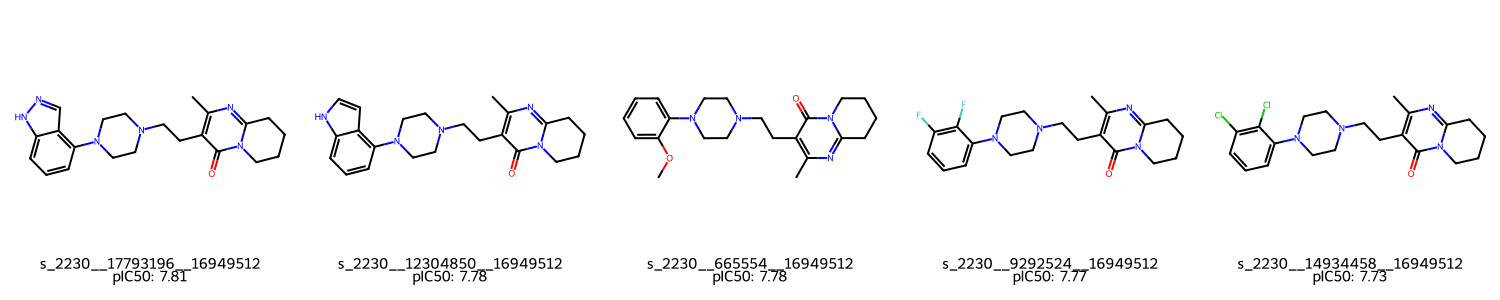

Top 5 random molecules


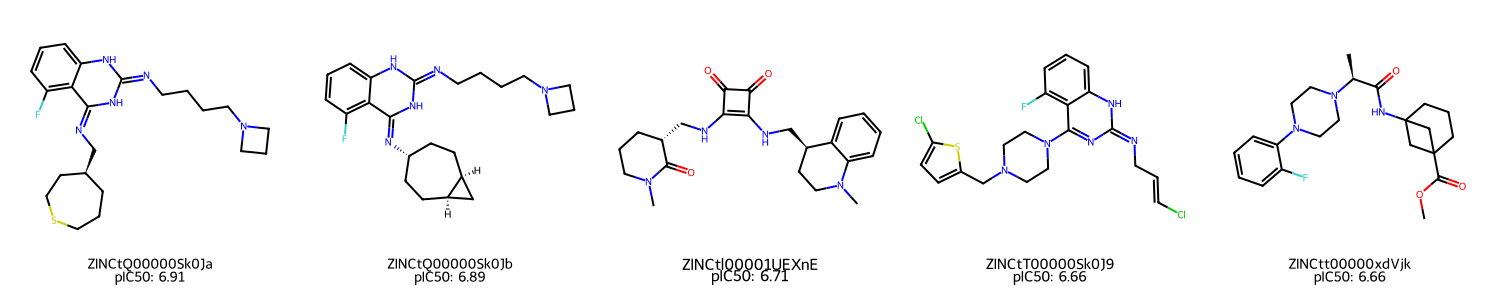

In [12]:
from rdkit import Chem
from rdkit.Chem import Draw

from IPython.display import SVG, display

for dataset_name, top5 in top5_by_dataset.items():
    mols_top5 = [Chem.MolFromSmiles(smile) for smile in top5["smiles"]]
    legends_top5 = [
        f"{cid}\npIC50: {pic50:.2f}"
        for cid, pic50 in zip(top5["compound_id"], top5["pred_pIC50"])
    ]
    print(f"Top 5 {dataset_name} molecules")
    svg = Draw.MolsToGridImage(
        mols_top5,
        molsPerRow=5,
        subImgSize=(300, 300),
        legends=legends_top5,
        useSVG=True,
    )
    if isinstance(svg, SVG):
        display(svg)
    else:
        display(SVG(svg))